# Phân tích dữ liệu Red Wine

## 1.1.3. Thống kê mô tả

### 1. Đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

# Nạp dữ liệu rượu đỏ
wine_data = pd.read_csv("data/winequality-red.csv")

print("Kích thước dữ liệu:", wine_data.shape)

wine_data.head()

Kích thước dữ liệu: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### 2. Kiểm tra dữ liệu

In [2]:
print("Kiểu dữ liệu:")
print(wine_data.dtypes)

print("\nSố giá trị thiếu:")
print(wine_data.isna().sum())

print("\nSố dòng trùng hoàn toàn:", wine_data.duplicated().sum())

print("\nSố quan sát theo điểm chất lượng:")
print(wine_data["quality"].value_counts().sort_index())

Kiểu dữ liệu:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Số giá trị thiếu:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Số dòng trùng hoàn toàn: 240

Số quan sát theo điểm chất lượng:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


### 3. Các chỉ số thống kê mô tả

Tính các chỉ số trên toàn bộ 1.599 mẫu.
Phương sai và độ lệch chuẩn sử dụng (Bảng ban đầu từ describe() sử dụng ddof=1 cho độ lệch chuẩn. Bảng hoàn chỉnh bên dưới cập nhật phương sai và độ lệch chuẩn với ddof=0).
Các giá trị mode đồng hạng được giữ đầy đủ.

In [3]:
# Thống kê mô tả, gồm phân vị 60% theo cách đã học
wine_summary = wine_data.describe(
    percentiles=[0.25, 0.50, 0.60, 0.75]
).T

wine_summary

,count,mean,std,min,25%,50%,60%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,8.300000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.570000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.320000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.300000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.082000,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,16.000000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,45.800000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997156,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.350000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.650000,0.730000,2.00000


In [4]:
# Cập nhật độ lệch chuẩn và bổ sung phương sai
wine_summary["std"] = wine_data.std(ddof=0)
wine_summary["variance"] = wine_data.var(ddof=0)

# Giữ tất cả mode nếu một biến có nhiều giá trị đồng hạng
wine_summary["mode"] = [
    wine_data[column].mode().tolist()
    for column in wine_summary.index
]

# Phạm vi và khoảng tứ phân vị
wine_summary["range"] = wine_summary["max"] - wine_summary["min"]
wine_summary["IQR"] = wine_summary["75%"] - wine_summary["25%"]

# Sắp xếp lại các cột
wine_summary = wine_summary[
    [
        "count", "mean", "50%", "mode", "variance", "std",
        "min", "max", "range", "25%", "60%", "75%", "IQR"
    ]
]

wine_summary

,count,mean,50%,mode,variance,std,min,max,range,25%,60%,75%,IQR
fixed acidity,1599.0,8.319637,7.90000,[7.2],3.029521,1.740552,4.60000,15.90000,11.30000,7.1000,8.300000,9.200000,2.100000
volatile acidity,1599.0,0.527821,0.52000,[0.6],0.032042,0.179004,0.12000,1.58000,1.46000,0.3900,0.570000,0.640000,0.250000
citric acid,1599.0,0.270976,0.26000,[0.0],0.037924,0.194740,0.00000,1.00000,1.00000,0.0900,0.320000,0.420000,0.330000
residual sugar,1599.0,2.538806,2.20000,[2.0],1.986654,1.409487,0.90000,15.50000,14.60000,1.9000,2.300000,2.600000,0.700000
chlorides,1599.0,0.087467,0.07900,[0.08],0.002214,0.047051,0.01200,0.61100,0.59900,0.0700,0.082000,0.090000,0.020000
free sulfur dioxide,1599.0,15.874922,14.00000,[6.0],109.346457,10.456886,1.00000,72.00000,71.00000,7.0000,16.000000,21.000000,14.000000
total sulfur dioxide,1599.0,46.467792,38.00000,[28.0],1081.425636,32.885037,6.00000,289.00000,283.00000,22.0000,45.800000,62.000000,40.000000
density,1599.0,0.996747,0.99675,[0.9972],0.000004,0.001887,0.99007,1.00369,0.01362,0.9956,0.997156,0.997835,0.002235
pH,1599.0,3.311113,3.31000,[3.3],0.023820,0.154338,2.74000,4.01000,1.27000,3.2100,3.350000,3.400000,0.190000
sulphates,1599.0,0.658149,0.62000,[0.6],0.028715,0.169454,0.33000,2.00000,1.67000,0.5500,0.650000,0.730000,0.180000


### 4. Xác định các điểm ngoài giới hạn IQR

Sử dụng giới hạn Q1 - 1,5 × IQR và Q3 + 1,5 × IQR.
Các điểm ngoài giới hạn được ghi nhận và giữ lại để phân tích.

In [5]:
q1 = wine_data.quantile(0.25)
q3 = wine_data.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (wine_data < lower_bound)
    | (wine_data > upper_bound)
)

wine_outliers = pd.DataFrame({
    "Giới hạn dưới": lower_bound,
    "Giới hạn trên": upper_bound,
    "Số giá trị ngoài giới hạn": outlier_mask.sum(),
    "Tỷ lệ (%)": outlier_mask.mean() * 100
})

wine_outliers

,Giới hạn dưới,Giới hạn trên,Số giá trị ngoài giới hạn,Tỷ lệ (%)
fixed acidity,3.950000,12.350000,49,3.064415
volatile acidity,0.015000,1.015000,19,1.188243
citric acid,-0.405000,0.915000,1,0.062539
residual sugar,0.850000,3.650000,155,9.693558
chlorides,0.040000,0.120000,112,7.004378
free sulfur dioxide,-14.000000,42.000000,30,1.876173
total sulfur dioxide,-38.000000,122.000000,55,3.439650
density,0.992248,1.001187,45,2.814259
pH,2.925000,3.685000,35,2.188868
sulphates,0.280000,1.000000,59,3.689806


### 5. Nhận xét thống kê mô tả



- Dữ liệu gồm 1.599 quan sát và 12 biến số, không có giá trị thiếu.
  Có 240 dòng trùng sau lần xuất hiện đầu tiên. Giữ nguyên các
  quan sát vì chưa có bằng chứng đây là lỗi ghi nhận.
- Điểm chất lượng nằm từ 3 đến 8, trung bình khoảng 5,64,
  trung vị là 6 và mode là 5. Các mức điểm 5 và 6 chiếm đa số.
- Alcohol có trung bình khoảng 10,42, trung vị 10,20;
  50% dữ liệu ở giữa nằm từ 9,50 đến 11,10.
- Residual sugar có trung bình khoảng 2,54, cao hơn trung vị 2,20.
  Giá trị lớn nhất là 15,50, trong khi Q3 là 2,60.
  Đây là dấu hiệu có đuôi phía giá trị lớn, cần xem biểu đồ
  để đánh giá rõ hơn.
- Theo quy tắc IQR, residual sugar có 155 giá trị ngoài giới hạn
  (9,69%), chlorides có 112 giá trị (7,00%).
  Đây là ngoại lai tiềm năng, chưa đồng nghĩa dữ liệu sai.
- Với quality, 28 quan sát điểm 3 hoặc 8 nằm ngoài giới hạn IQR,
  nhưng vẫn là điểm đánh giá hợp lệ.
- Phương sai và độ lệch chuẩn được tính với ddof=0.
  Các biến có đơn vị và thang đo khác nhau nên không so sánh
  trực tiếp độ lệch chuẩn để kết luận biến nào phân tán hơn.

## 1.2.2. Trực quan hóa dữ liệu Red Wine

### Phân bố điểm chất lượng rượu

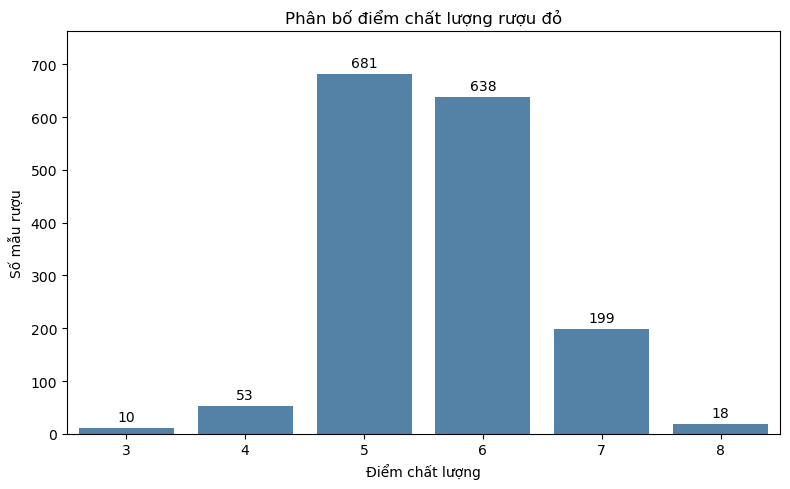

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=wine_data,
    x="quality",
    order=sorted(wine_data["quality"].unique()),
    color="steelblue",
    ax=ax
)

ax.set_title("Phân bố điểm chất lượng rượu đỏ")
ax.set_xlabel("Điểm chất lượng")
ax.set_ylabel("Số mẫu rượu")

# Hiển thị số mẫu trên từng cột
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.12)

fig.tight_layout()
plt.show()

### Phân bố các đặc trưng của rượu đỏ

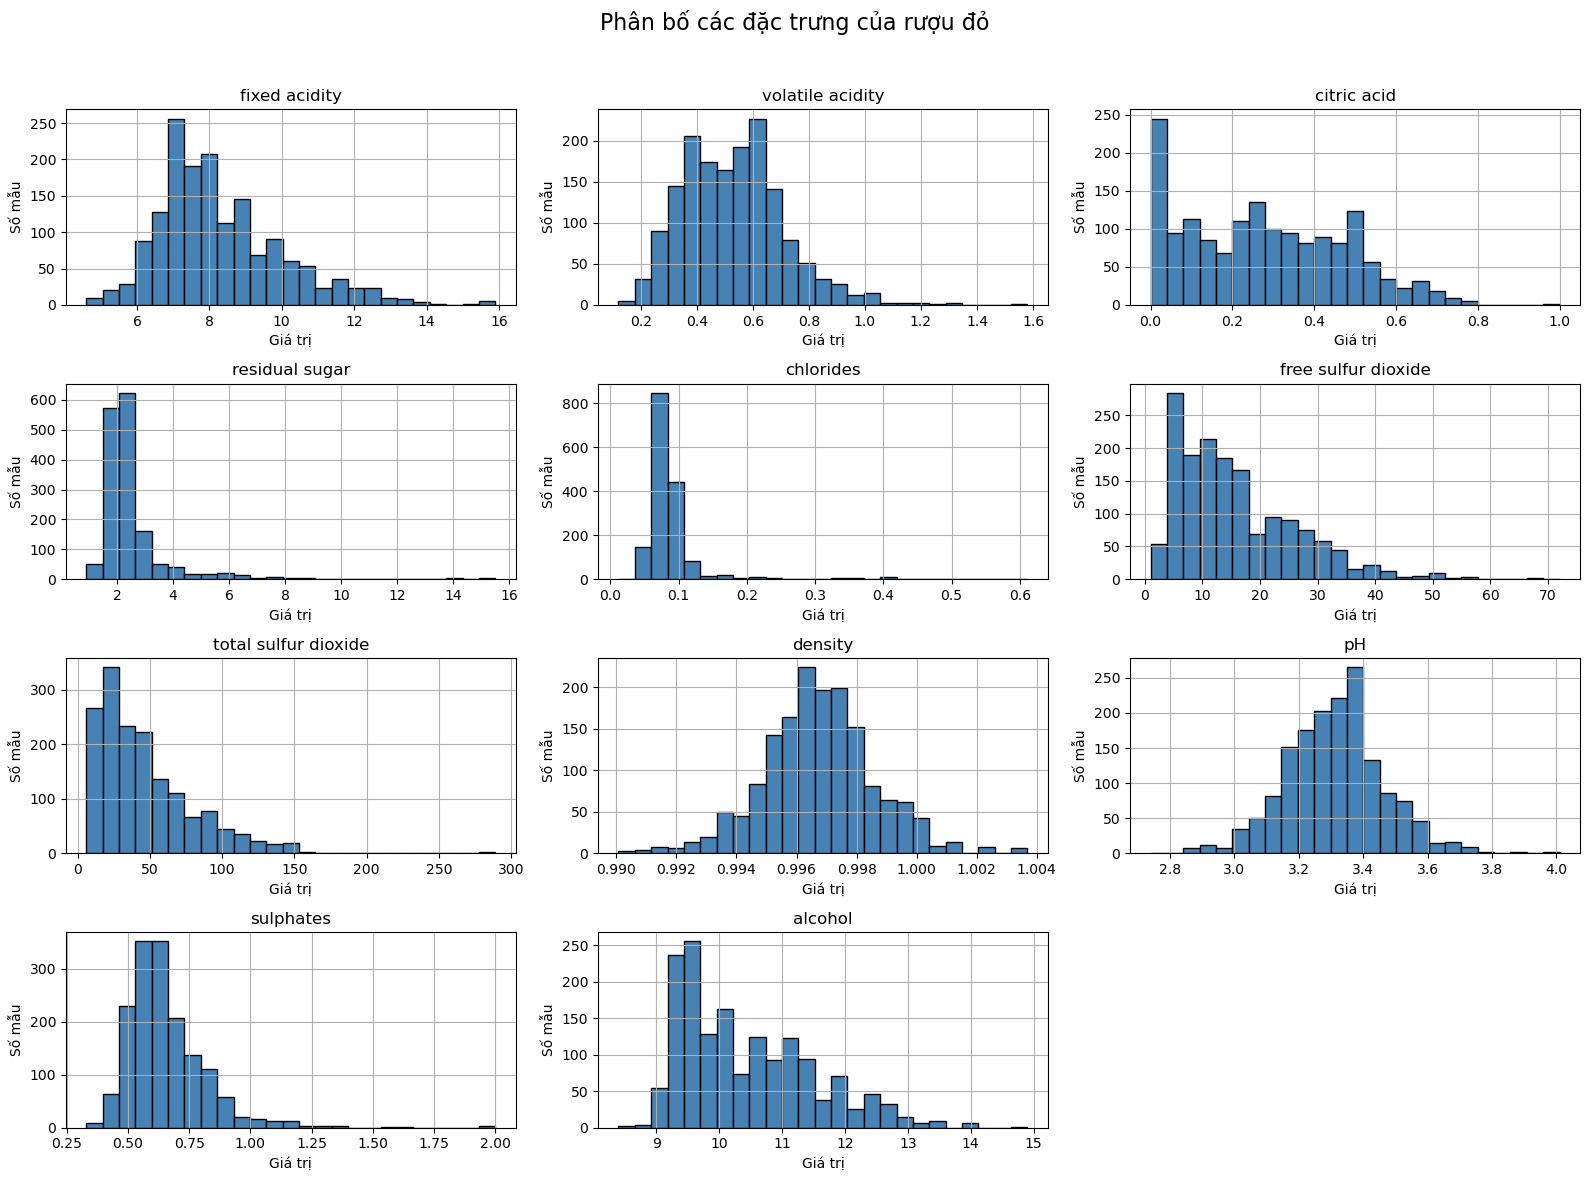

In [7]:
# Tách các đặc trưng, không đưa điểm quality vào histogram
wine_features = wine_data.drop(columns="quality")

wine_features.hist(
    bins=25,
    figsize=(16, 12),
    layout=(4, 3),
    color="steelblue",
    edgecolor="black"
)

fig = plt.gcf()
fig.suptitle("Phân bố các đặc trưng của rượu đỏ", fontsize=16)

for ax in fig.axes:
    if ax.get_visible():
        ax.set_xlabel("Giá trị")
        ax.set_ylabel("Số mẫu")

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Boxplot các đặc trưng của rượu đỏ

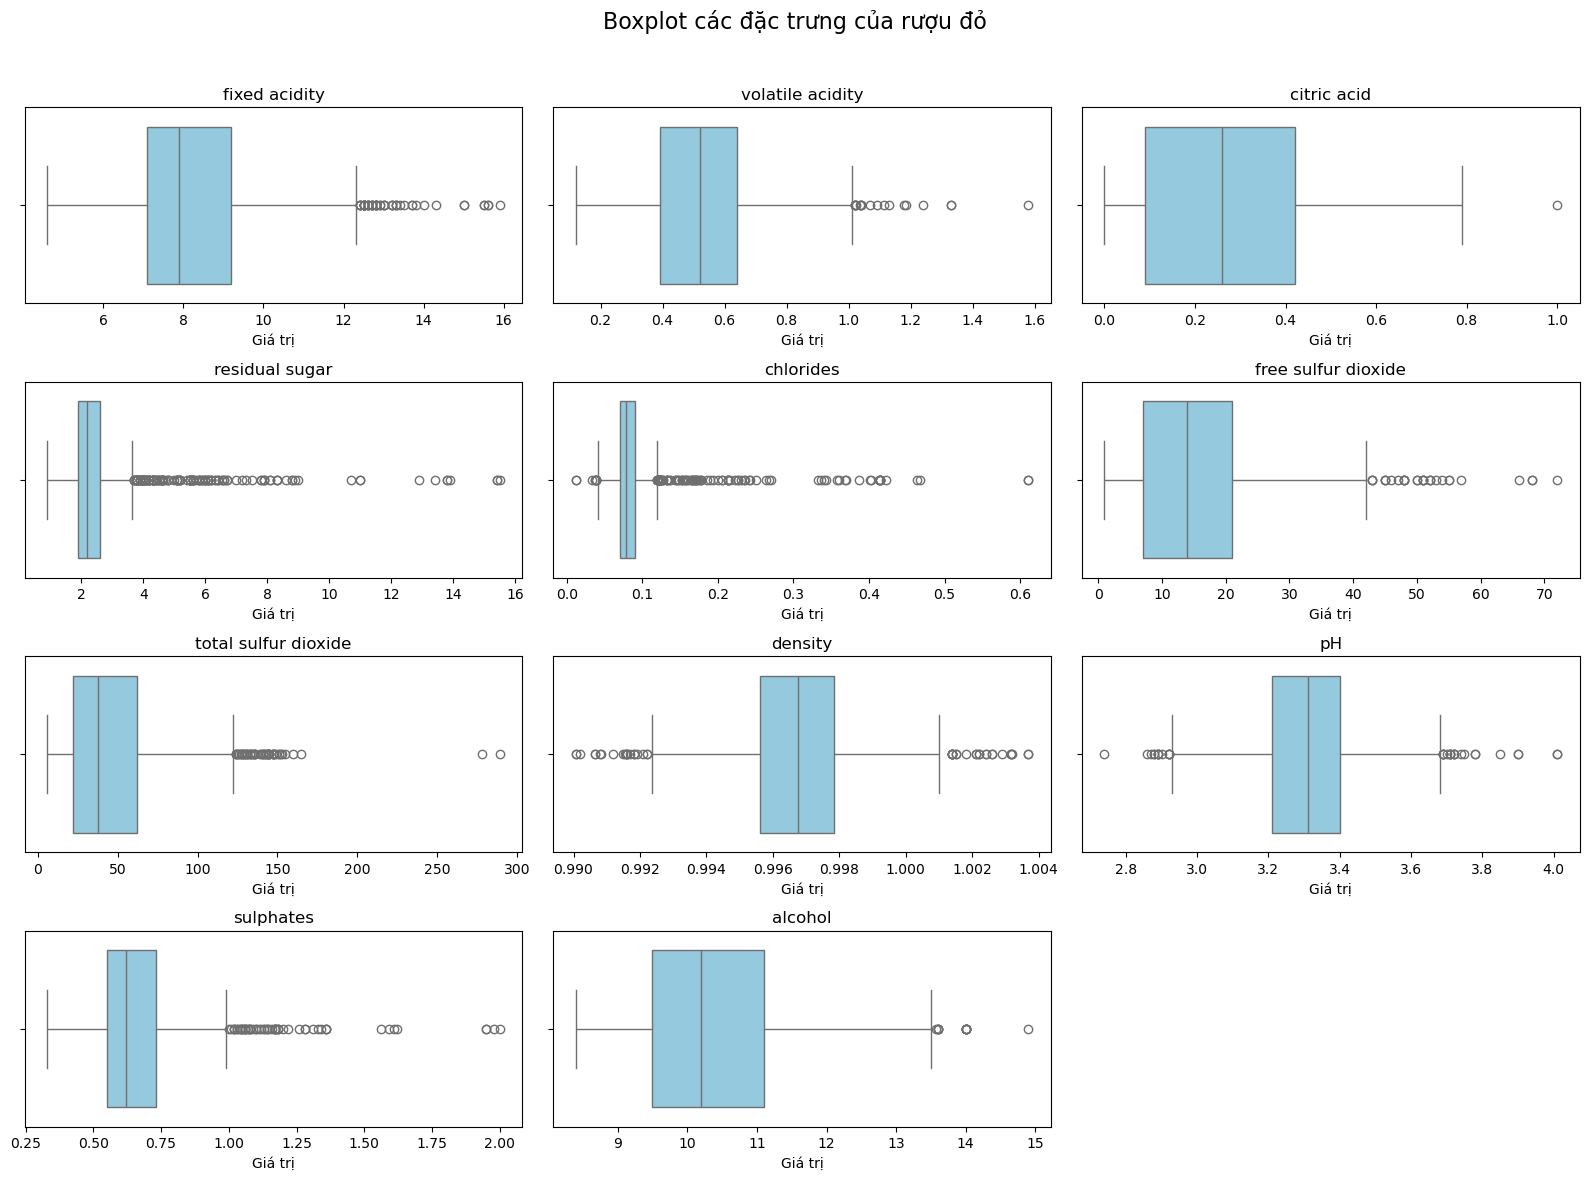

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12))
axes = axes.ravel()

for ax, column in zip(axes, wine_features.columns):
    sns.boxplot(
        data=wine_features,
        x=column,
        color="skyblue",
        whis=1.5,
        ax=ax
    )
    ax.set_title(column)
    ax.set_xlabel("Giá trị")

# Ẩn ô dư
for ax in axes[len(wine_features.columns):]:
    ax.set_visible(False)

fig.suptitle("Boxplot các đặc trưng của rượu đỏ", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Nồng độ cồn theo điểm chất lượng rượu

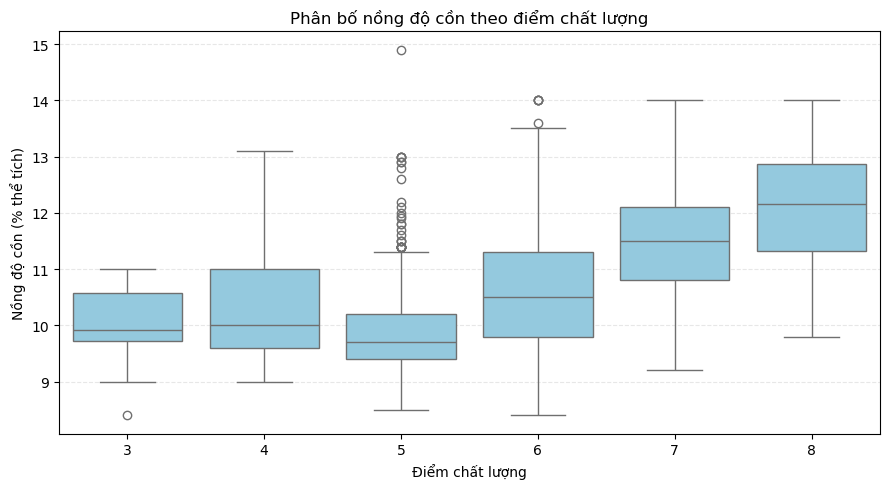

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=wine_data,
    x="quality",
    y="alcohol",
    order=sorted(wine_data["quality"].unique()),
    color="skyblue",
    ax=ax
)

ax.set_title("Phân bố nồng độ cồn theo điểm chất lượng")
ax.set_xlabel("Điểm chất lượng")
ax.set_ylabel("Nồng độ cồn (% thể tích)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Mối liên hệ giữa nồng độ cồn và độ axit bay hơi

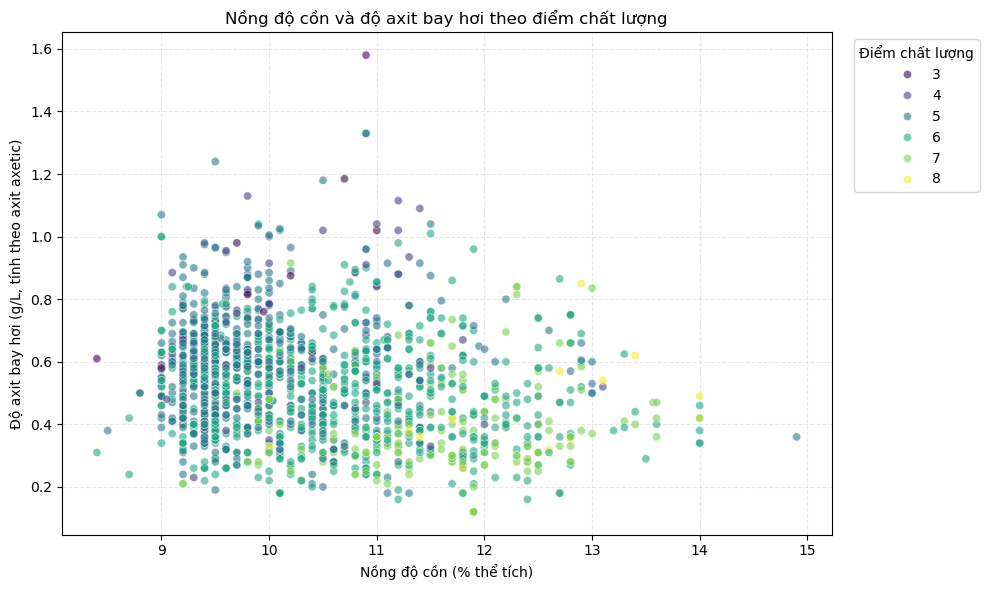

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=wine_data,
    x="alcohol",
    y="volatile acidity",
    hue="quality",
    palette="viridis",
    alpha=0.6,
    s=35,
    ax=ax
)

ax.set_title("Nồng độ cồn và độ axit bay hơi theo điểm chất lượng")
ax.set_xlabel("Nồng độ cồn (% thể tích)")
ax.set_ylabel("Độ axit bay hơi (g/L, tính theo axit axetic)")
ax.legend(title="Điểm chất lượng", bbox_to_anchor=(1.02, 1),
          loc="upper left")
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Ma trận tương quan giữa các biến

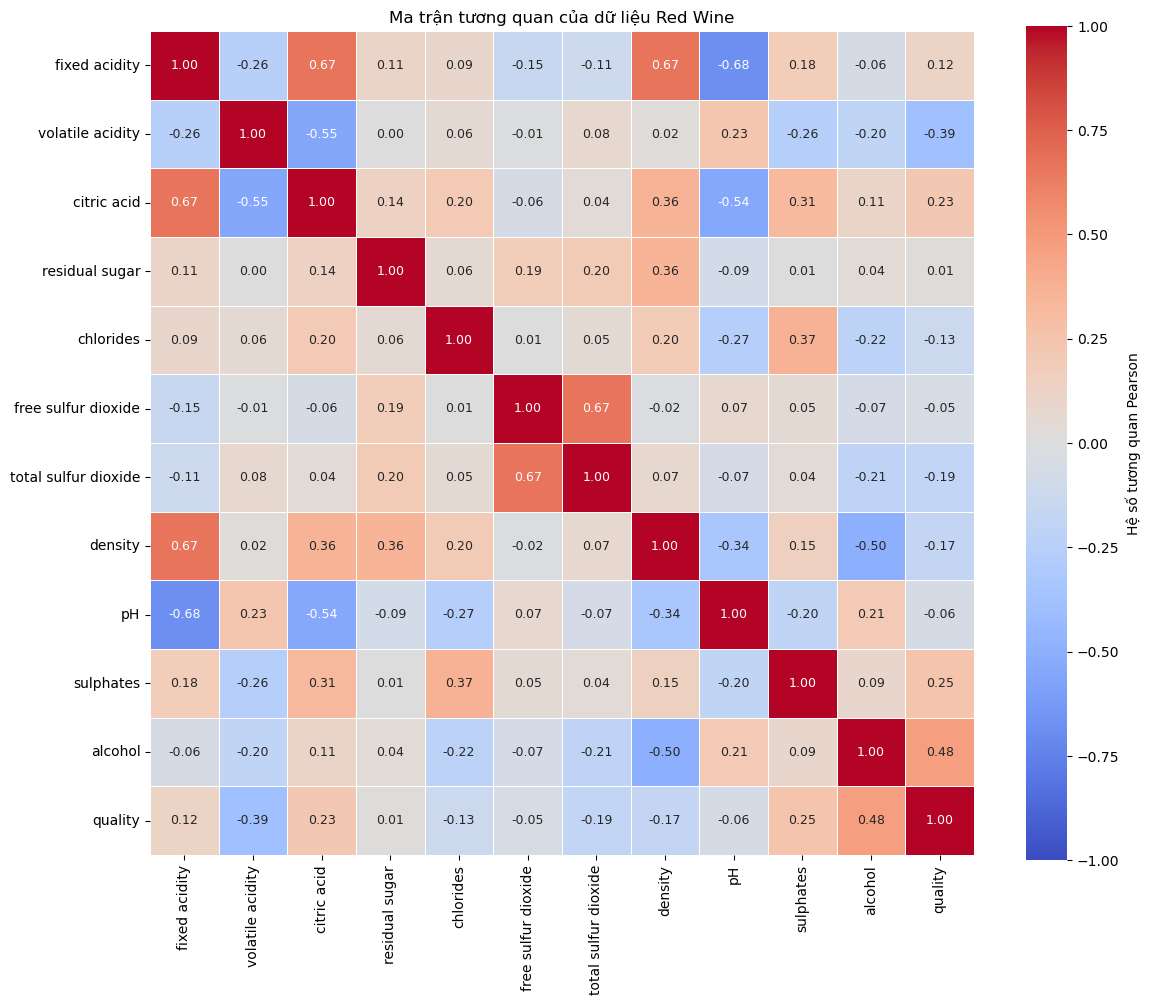

In [11]:
# Tính hệ số tương quan Pearson
wine_corr = wine_data.corr(method="pearson")

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    wine_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 9},
    cbar_kws={"label": "Hệ số tương quan Pearson"},
    ax=ax
)

ax.set_title("Ma trận tương quan của dữ liệu Red Wine")
fig.tight_layout()
plt.show()

### Nhận xét về trực quan hóa

- Điểm chất lượng tập trung chủ yếu ở mức 5 và 6, với tổng
  1.319 mẫu, chiếm khoảng 82,49% dữ liệu. Các nhóm điểm 3 và 8
  có ít mẫu nên cần thận trọng khi so sánh.
- Histogram cho thấy nhiều đặc trưng có phân bố lệch phải,
  nổi bật là residual sugar, chlorides và total sulfur dioxide.
  Density và pH có hình dạng khá đối xứng, nhưng chưa đủ
  căn cứ để kết luận có phân bố chuẩn.
- Boxplot thể hiện nhiều điểm ngoài giới hạn 1,5 × IQR,
  đặc biệt ở residual sugar và chlorides. Những điểm này
  được giữ lại vì chưa có bằng chứng chúng là dữ liệu sai.
- Trung vị nồng độ cồn tăng dần từ nhóm điểm 5 đến 8.
  Tuy nhiên, phân bố giữa các nhóm vẫn chồng lấn.
- Scatter plot cho thấy các mẫu có điểm chất lượng cao thường
  xuất hiện ở vùng nồng độ cồn cao và độ axit bay hơi thấp hơn,
  nhưng các nhóm chưa tách biệt rõ ràng.
- Trong các đặc trưng, alcohol có tương quan Pearson với
  quality lớn nhất về trị tuyệt đối, khoảng 0,48.
  Volatile acidity có tương quan nghịch khoảng -0,39.
  Sulphates có tương quan thuận khoảng 0,25.
- Fixed acidity và pH có tương quan nghịch khoảng -0,68;
  free sulfur dioxide và total sulfur dioxide có tương quan
  thuận khoảng 0,67.
- Các kết quả mô tả mối liên hệ trong bộ dữ liệu, không chứng minh
  quan hệ nhân quả. Pearson với điểm quality được dùng để
  khảo sát ban đầu vì quality là biến có thứ bậc.